# Netflix Movies & TV Shows: Exploratory Data Analysis

## 1. Introduction

This notebook explores the **Netflix Movies and TV Shows** dataset published on Kaggle by Shivam Bansal:
<https://www.kaggle.com/datasets/shivamb/netflix-shows>.

Each row is one title that was on Netflix when the snapshot was taken (mid-2021). Columns cover the title's type (Movie / TV Show), director, cast, production country, the date it was added to Netflix, release year, maturity rating, duration, genres (`listed_in`) and a short description.

**Questions this analysis answers**

1. How is the catalogue split between movies and TV shows, and has that mix shifted over the years?
2. How quickly did Netflix grow its catalogue, measured by titles added per year?
3. Which countries produce the most content, and does the movie/TV mix differ by country?
4. How long are movies, and how many seasons do TV shows usually run?
5. Which genres and audience-maturity ratings dominate, and do they differ between movies and TV shows?
6. How old is content when Netflix adds it, and which months see the most additions?

**Tools:** Python, Pandas, Matplotlib and Seaborn.

In [1]:
import calendar
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# One consistent plotting style for every chart in the notebook
sns.set_theme(style="whitegrid", context="notebook",
              rc={"axes.spines.top": False, "axes.spines.right": False,
                  "axes.titleweight": "bold", "axes.titlesize": 13})

# Fixed colours: each content type always gets the same hue
BLUE, ORANGE = "#2a78d6", "#eb6834"
TYPE_COLORS = {"Movie": BLUE, "TV Show": ORANGE}

DATA_PATH = Path("data/netflix_titles.csv")
IMAGE_DIR = Path("images")
IMAGE_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

In [2]:
# ---------- Helper functions (reused throughout to avoid repeated code) ----------

def style_ax(ax, title, xlabel, ylabel):
    # Give every chart a title and labelled axes.
    ax.set_title(title, loc="left")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)


def save_and_show(fig, filename):
    # Tidy the layout, save a PNG copy to images/, then display the figure.
    fig.tight_layout()
    fig.savefig(IMAGE_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()


def label_bars(ax, fmt="{:,.0f}"):
    # Write each bar's value at its end.
    for container in ax.containers:
        ax.bar_label(container, fmt=fmt, padding=3, fontsize=9)


def counts_table(series, n=None):
    # value_counts() with a percentage column; optionally keep only the top n.
    counts = series.value_counts()
    table = pd.DataFrame({"count": counts, "pct": (counts / counts.sum() * 100).round(2)})
    return table.head(n) if n else table

## 2. Structural overview

Load the raw CSV with a relative path and inspect its structure before any charts.

In [3]:
df = pd.read_csv(DATA_PATH)
print("Shape (rows, columns):", df.shape)

Shape (rows, columns): (8807, 12)


In [4]:
df.dtypes

show_id           str
type              str
title             str
director          str
cast              str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
description       str
dtype: object

In [5]:
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 7.8 MB


In [6]:
memory_mb = df.memory_usage(deep=True).sum() / 1024**2
print(f"Memory usage: {memory_mb:.2f} MB")

Memory usage: 7.79 MB


In [7]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [8]:
df.tail()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."
8806,s8807,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,"March 2, 2019",2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a ty...


In [9]:
exact_dupes = df.duplicated().sum()
# A looser check: same title, type and release year listed twice
title_dupes = df.duplicated(subset=["title", "type", "release_year"]).sum()
print(f"Exact duplicate rows: {exact_dupes}")
print(f"Duplicate (title, type, release_year) combinations: {title_dupes}")
print(f"Unique show_id values: {df['show_id'].nunique():,} of {len(df):,}")

Exact duplicate rows: 0
Duplicate (title, type, release_year) combinations: 0
Unique show_id values: 8,807 of 8,807


**Takeaways.** The raw file has **8,807 rows and 12 columns** and uses about **7.8 MB** in memory. Only `release_year` is numeric. Every other column, including `date_added` and `duration`, is stored as text and has to be parsed. The file has **no duplicate rows**, even on the looser (title, type, release year) check, and every `show_id` is unique.

## 3. Missing value analysis

In [10]:
missing = (df.isna().sum().to_frame("missing_count")
             .assign(missing_pct=lambda t: (t["missing_count"] / len(df) * 100).round(2))
             .sort_values("missing_count", ascending=False))
missing

,missing_count,missing_pct
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03
show_id,0,0.00
type,0,0.00
title,0,0.00
release_year,0,0.00


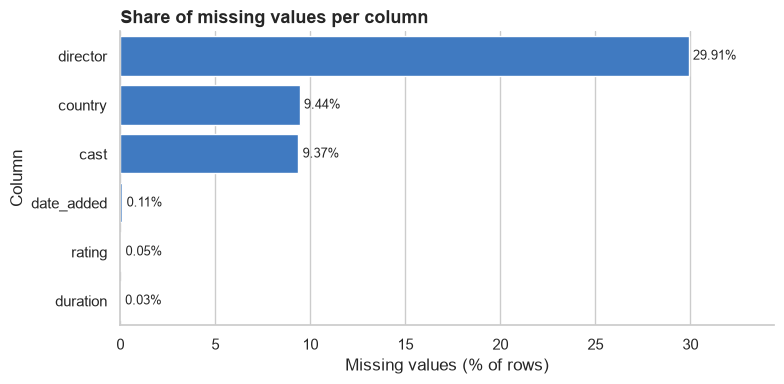

In [11]:
affected = missing[missing["missing_count"] > 0]

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=affected["missing_pct"], y=affected.index, color=BLUE, ax=ax)
label_bars(ax, fmt="{:.2f}%")
style_ax(ax, "Share of missing values per column", "Missing values (% of rows)", "Column")
ax.set_xlim(0, affected["missing_pct"].max() * 1.15)
save_and_show(fig, "01_missing_pct.png")

Only six columns have gaps. `director` is by far the worst (**29.91%** missing), followed by `country` (**9.44%**) and `cast` (**9.37%**). `date_added` (10 rows), `rating` (4) and `duration` (3) are almost complete.

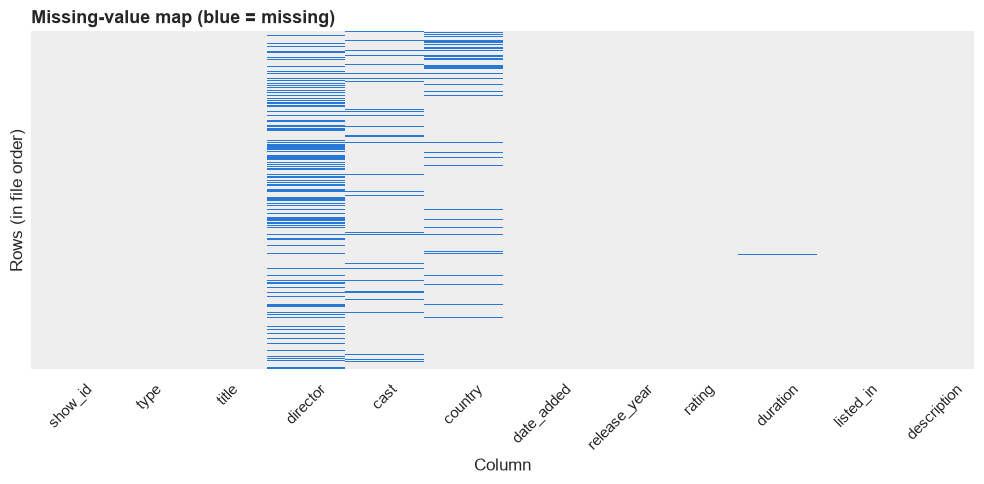

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(df.isna(), cbar=False, yticklabels=False,
            cmap=sns.color_palette(["#eeeeee", BLUE], as_cmap=True), ax=ax)
style_ax(ax, "Missing-value map (blue = missing)", "Column", "Rows (in file order)")
ax.tick_params(axis="x", rotation=45)
save_and_show(fig, "02_missing_heatmap.png")

In [13]:
# Is missingness random, or does it depend on the type of title?
missing_by_type = (df.groupby("type")[["director", "cast", "country"]]
                     .agg(lambda col: col.isna().mean() * 100).round(1))
missing_by_type.columns = [f"{c}_missing_pct" for c in missing_by_type.columns]
missing_by_type

,director_missing_pct,cast_missing_pct,country_missing_pct
type,,,
Movie,3.1,7.7,7.2
TV Show,91.4,13.1,14.6


The heatmap shows that missing `director` values are much denser in the first two-thirds of the file, and all 10 missing `date_added` values fall in the last third of the file (all of them TV shows), so the gaps aren't spread evenly. The table by type explains why: **91.4% of TV shows have no director**, compared with **3.1% of movies**. TV series usually have a different director for each episode, so Netflix leaves the field empty, which means these values are missing *structurally*, not at random. `cast` and `country` are also missing about twice as often for TV shows (13.1% and 14.6%) as for movies (7.7% and 7.2%). That fits documentaries, stand-up and animated titles, which often have no credited cast or a single country of origin.

**How each column is handled**

| Column | Missing | Handling | Why |
|---|---|---|---|
| `director` | 29.91% | Fill with `"Unknown"` | Too many rows to drop, and the gaps are structural (TV shows). Imputing a name would invent data. |
| `country` | 9.44% | Fill with `"Unknown"` | Keep the rows for every other analysis. `"Unknown"` is excluded from the country rankings. |
| `cast` | 9.37% | Fill with `"Unknown"` | Same reasoning; cast isn't used in any numeric analysis. |
| `date_added` | 10 rows (0.11%) | **Drop the rows** | `year_added`, `month_added` and `content_age` all depend on this date, and there's no reliable way to impute it. |
| `rating` | 4 rows + 3 shifted | Fill with `"Unknown"` | Section 4 shows that 3 "ratings" are actually runtimes. Once those are moved back to `duration`, those 3 titles plus the 4 originally missing (7 in total) are labelled `"Unknown"`. That keeps their valid runtime and genre data, and 7 rows are too few to distort the rating distribution. |
| `duration` | 3 rows | Recover from `rating` | These are the same 3 shifted rows, so the true value already sits in `rating`. |

## 4. Cleaning and feature engineering

In [14]:
# Bad values: some `rating` cells contain durations such as "74 min"
shifted = df["rating"].str.contains("min", na=False)
df.loc[shifted, ["show_id", "title", "rating", "duration"]]

,show_id,title,rating,duration
5541,s5542,Louis C.K. 2017,74 min,NaN
5794,s5795,Louis C.K.: Hilarious,84 min,NaN
5813,s5814,Louis C.K.: Live at the Comedy Store,66 min,NaN


These three Louis C.K. stand-up specials have their runtime stored in `rating`, and their `duration` is empty, so the value was entered in the wrong column. The cleaning step moves each value back to `duration` and marks the rating as unknown.

In [15]:
clean = df.copy()
rows_before = len(clean)

# 1. Fix the shifted values: move the runtime back to `duration`, mark rating unknown
clean.loc[shifted, "duration"] = clean.loc[shifted, "rating"]
clean.loc[shifted, "rating"] = np.nan

# 2. Fill categorical gaps with an explicit "Unknown" label
for col in ["director", "cast", "country", "rating"]:
    clean[col] = clean[col].fillna("Unknown")

# 3. Drop the rows with no date_added (needed for all time-based features)
clean = clean.dropna(subset=["date_added"])

# 4. Parse date_added; some values have a leading space, e.g. " August 4, 2017"
clean["date_added"] = pd.to_datetime(clean["date_added"].str.strip(), format="%B %d, %Y")
clean["year_added"] = clean["date_added"].dt.year
clean["month_added"] = clean["date_added"].dt.month

print(f"Rows: {rows_before:,} -> {len(clean):,} (dropped {rows_before - len(clean)} with no date_added)")
print(f"Shifted ratings fixed: {shifted.sum()}")
print(f"date_added range: {clean['date_added'].min():%d %b %Y} to {clean['date_added'].max():%d %b %Y}")

Rows: 8,807 -> 8,797 (dropped 10 with no date_added)
Shifted ratings fixed: 3
date_added range: 01 Jan 2008 to 25 Sep 2021


In [16]:
# 5. Split `duration` ("90 min", "1 Season", "3 Seasons") into a number and a unit
parts = clean["duration"].str.extract(r"^(\d+)\s+(min|Seasons?)$")
assert parts.notna().all().all(), "Unexpected duration format"

clean["duration_value"] = parts[0].astype(int)
clean["duration_unit"] = parts[1].replace({"Season": "Seasons"})

# Movies are measured in minutes and TV shows in seasons; each is NaN for the other type
clean["duration_minutes"] = clean["duration_value"].where(clean["type"].eq("Movie"))
clean["num_seasons"] = clean["duration_value"].where(clean["type"].eq("TV Show"))

# Sanity check: every movie is in minutes, every TV show in seasons
pd.crosstab(clean["type"], clean["duration_unit"])

duration_unit,Seasons,min
type,,
Movie,0,6131
TV Show,2666,0


In [17]:
# 6. Primary country = the first non-empty country in the comma-separated list
def first_country(countries):
    names = [c.strip() for c in countries.split(",") if c.strip()]
    return names[0] if names else "Unknown"

clean["primary_country"] = clean["country"].map(first_country)
multi_country = clean["country"].str.contains(",").mean() * 100
print(f"Titles listing more than one country: {multi_country:.1f}%")

# 7. Content age: how many years old a title was when it was added to Netflix
clean["content_age"] = clean["year_added"] - clean["release_year"]
negative_age = clean[clean["content_age"] < 0]
print(f"Titles with negative content_age (added before their release year): {len(negative_age)}")
negative_age[["title", "type", "release_year", "date_added", "content_age"]].head()

Titles listing more than one country: 15.0%
Titles with negative content_age (added before their release year): 14


,title,type,release_year,date_added,content_age
1551,Hilda,TV Show,2021,2020-12-14,-1
1696,Polly Pocket,TV Show,2021,2020-11-15,-1
2920,Love Is Blind,TV Show,2021,2020-02-13,-1
3168,Fuller House,TV Show,2020,2019-12-06,-1
3287,Maradona in Mexico,TV Show,2020,2019-11-13,-1


A handful of titles appear to be added *before* their release year (content_age between -1 and -3). These are most likely upcoming originals listed early, or errors in `release_year`. There are too few to matter, so they're kept as they are and flagged here.

In [18]:
# 8. Explode the comma-separated genres into one row per (title, genre)
genres = (clean.assign(genre=clean["listed_in"].str.split(","))
               .explode("genre")
               .assign(genre=lambda t: t["genre"].str.strip()))
print(f"{len(clean):,} titles -> {len(genres):,} title-genre rows "
      f"({len(genres) / len(clean):.2f} genres per title on average)")
print(f"Remaining missing values in the cleaned table:\n{clean.isna().sum()[lambda s: s > 0]}")

8,797 titles -> 19,303 title-genre rows (2.19 genres per title on average)
Remaining missing values in the cleaned table:
duration_minutes    2666
num_seasons         6131
dtype: int64


**What was fixed or added**

- Moved **3** runtimes that had been stored in `rating` back into `duration`.
- Filled `director`, `cast`, `country` and `rating` gaps with `"Unknown"`, and dropped the **10** rows with no `date_added` (all TV shows).
- Stripped leading whitespace from `date_added`, parsed it to datetime, and derived `year_added` and `month_added`.
- Split `duration` into `duration_value` (int) and `duration_unit`. Movies get `duration_minutes` and TV shows get `num_seasons`. The only NaNs left are by design: `num_seasons` is empty for movies and `duration_minutes` is empty for TV shows.
- Derived `primary_country` (the first country listed; 15% of titles list several), `content_age`, and a long-format `genres` table.

## 5. Summary statistics

In [19]:
NUMERIC_COLS = ["release_year", "year_added", "month_added", "duration_minutes", "num_seasons", "content_age"]
clean[NUMERIC_COLS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
release_year,8797.0,2014.18,8.82,1925.0,2013.0,2017.0,2019.0,2021.0
year_added,8797.0,2018.87,1.57,2008.0,2018.0,2019.0,2020.0,2021.0
month_added,8797.0,6.65,3.44,1.0,4.0,7.0,10.0,12.0
duration_minutes,6131.0,99.56,28.29,3.0,87.0,98.0,114.0,312.0
num_seasons,2666.0,1.75,1.55,1.0,1.0,1.0,2.0,17.0
content_age,8797.0,4.69,8.79,-3.0,0.0,1.0,5.0,93.0


In [20]:
# Explicit mean, median, standard deviation and quartiles
stats = clean[NUMERIC_COLS].agg(["mean", "median", "std"]).T
quartiles = clean[NUMERIC_COLS].quantile([0.25, 0.5, 0.75]).T
quartiles.columns = ["Q1 (25%)", "Q2 (50%)", "Q3 (75%)"]
stats.join(quartiles).round(2)

,mean,median,std,Q1 (25%),Q2 (50%),Q3 (75%)
release_year,2014.18,2017.0,8.82,2013.0,2017.0,2019.0
year_added,2018.87,2019.0,1.57,2018.0,2019.0,2020.0
month_added,6.65,7.0,3.44,4.0,7.0,10.0
duration_minutes,99.56,98.0,28.29,87.0,98.0,114.0
num_seasons,1.75,1.0,1.55,1.0,1.0,2.0
content_age,4.69,1.0,8.79,0.0,1.0,5.0


In [21]:
counts_table(clean['type'])

,count,pct
type,,
Movie,6131,69.69
TV Show,2666,30.31


In [22]:
counts_table(clean['rating'])

,count,pct
rating,,
TV-MA,3205,36.43
TV-14,2157,24.52
TV-PG,861,9.79
R,799,9.08
PG-13,490,5.57
TV-Y7,333,3.79
TV-Y,306,3.48
PG,287,3.26
TV-G,220,2.50


In [23]:
counts_table(clean['primary_country'], n=10)

,count,pct
primary_country,,
United States,3205,36.43
India,1008,11.46
Unknown,830,9.44
United Kingdom,627,7.13
Canada,271,3.08
Japan,258,2.93
France,213,2.42
South Korea,212,2.41
Spain,181,2.06


In [24]:
counts_table(genres['genre'], n=10)

,count,pct
genre,,
International Movies,2752,14.26
Dramas,2427,12.57
Comedies,1674,8.67
International TV Shows,1350,6.99
Documentaries,869,4.50
Action & Adventure,859,4.45
TV Dramas,762,3.95
Independent Movies,756,3.92
Children & Family Movies,641,3.32


### Outlier check (IQR method)

A value counts as an outlier if it falls below Q1 − 1.5·IQR or above Q3 + 1.5·IQR.

In [25]:
def iqr_outliers(series):
    # Summarise IQR fences and how many values fall outside them.
    s = series.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((s < low) | (s > high)).sum()
    return pd.Series({"Q1": q1, "Q3": q3, "IQR": iqr, "lower_fence": low, "upper_fence": high,
                      "min": s.min(), "max": s.max(), "n_outliers": n_out,
                      "pct_outliers": round(n_out / len(s) * 100, 1)})

OUTLIER_COLS = ["release_year", "duration_minutes", "num_seasons", "content_age"]
outliers = pd.DataFrame({col: iqr_outliers(clean[col]) for col in OUTLIER_COLS}).T
outliers

,Q1,Q3,IQR,lower_fence,upper_fence,min,max,n_outliers,pct_outliers
release_year,2013.0,2019.0,6.0,2004.0,2028.0,1925.0,2021.0,717.0,8.2
duration_minutes,87.0,114.0,27.0,46.5,154.5,3.0,312.0,450.0,7.3
num_seasons,1.0,2.0,1.0,-0.5,3.5,1.0,17.0,254.0,9.5
content_age,0.0,5.0,5.0,-7.5,12.5,-3.0,93.0,972.0,11.0


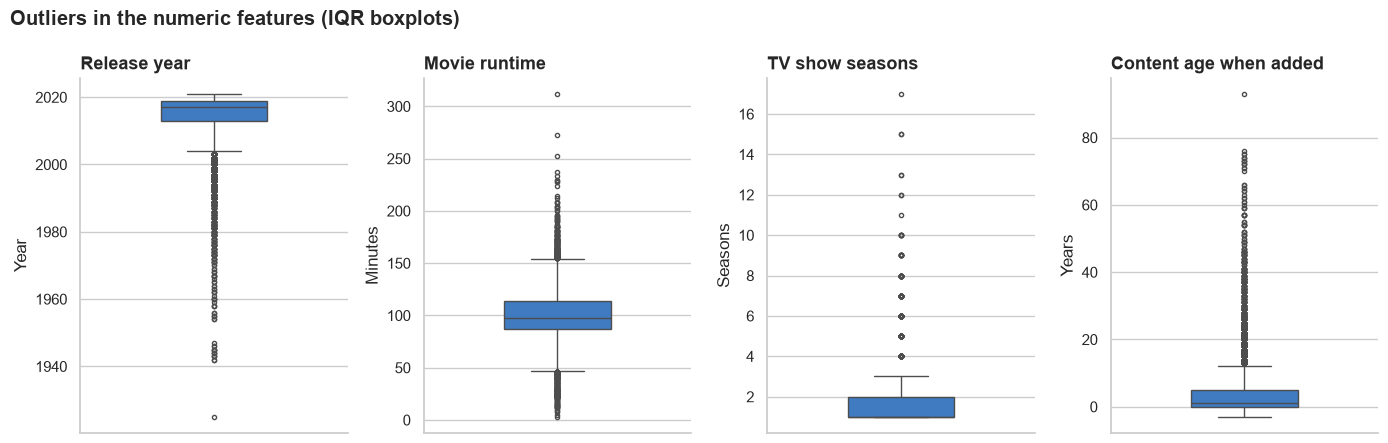

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4.5))
titles = {"release_year": ("Release year", "Year"),
          "duration_minutes": ("Movie runtime", "Minutes"),
          "num_seasons": ("TV show seasons", "Seasons"),
          "content_age": ("Content age when added", "Years")}
for ax, col in zip(axes, OUTLIER_COLS):
    sns.boxplot(y=clean[col].dropna(), color=BLUE, width=0.4, fliersize=3, ax=ax)
    style_ax(ax, titles[col][0], "", titles[col][1])
fig.suptitle("Outliers in the numeric features (IQR boxplots)", fontweight="bold", x=0.01, ha="left")
save_and_show(fig, "03_outlier_boxplots.png")

**Outlier comments.**
- **Movie runtime:** the middle 50% run 87–114 minutes, and **450 movies (7.3%)** fall outside the fences. The range goes from a 3-minute short to a 312-minute epic. These are real titles (shorts, stand-up specials, long Indian films), not errors, so they're kept.
- **TV seasons:** the IQR is 1–2 seasons, so anything with **4 or more seasons** counts as an outlier: **254 shows (9.5%)**, up to 17 seasons. Long-running series are exactly what this flags, and they're kept too.
- **Release year / content age:** **717 titles (8.2%)** were released before about 2004, going back as far as 1925, and **972 (11.0%)** were more than 12 years old when added (max 93). This is a long tail of classic catalogue titles. It's skewed rather than erroneous, which is why the median is used for content age below.

## 6. Visualisations

Each chart answers one question. Every figure is also saved to `images/`.

### Q1. Movies vs TV shows: what's the split, and how has it changed by year added?

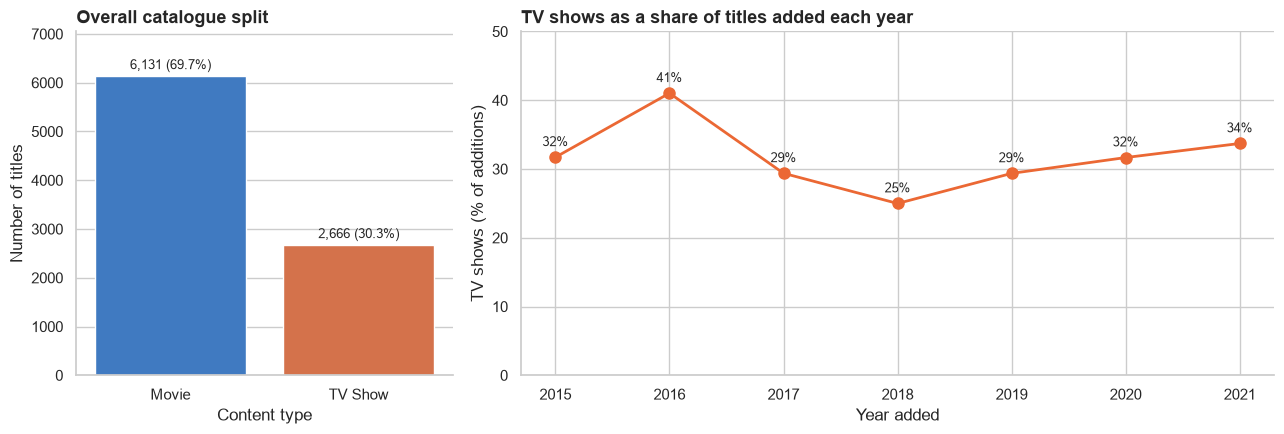

type
Movie      69.7
TV Show    30.3

TV share by year (%): {2015: 31.7, 2016: 41.0, 2017: 29.4, 2018: 25.0, 2019: 29.4, 2020: 31.7, 2021: 33.7}


In [27]:
type_share = clean["type"].value_counts(normalize=True) * 100
by_year = pd.crosstab(clean["year_added"], clean["type"])
tv_share = (by_year["TV Show"] / by_year.sum(axis=1) * 100)[by_year.sum(axis=1) >= 50]  # years with ≥50 additions

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 2]})

counts = clean["type"].value_counts()
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette=TYPE_COLORS, legend=False, ax=ax1)
for container, share in zip(ax1.containers, type_share[counts.index]):
    ax1.bar_label(container, labels=[f"{container.datavalues[0]:,.0f} ({share:.1f}%)"], padding=3, fontsize=9)
style_ax(ax1, "Overall catalogue split", "Content type", "Number of titles")
ax1.set_ylim(0, counts.max() * 1.15)

ax2.plot(tv_share.index, tv_share.values, color=ORANGE, marker="o", linewidth=2, markersize=8)
for x, y in tv_share.items():
    ax2.annotate(f"{y:.0f}%", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
style_ax(ax2, "TV shows as a share of titles added each year", "Year added", "TV shows (% of additions)")
ax2.set_ylim(0, 50)
ax2.set_xticks(tv_share.index)
save_and_show(fig, "04_movies_vs_tv.png")

print(type_share.round(1).to_string())
print("\nTV share by year (%):", tv_share.round(1).to_dict())

Movies make up **69.7%** of the catalogue (6,131 titles) and TV shows **30.3%** (2,666). The TV share of new additions is not stable: it peaked at **41%** in 2016, fell to **25%** in 2018 as Netflix added movies in bulk, then rose every year to **33.7%** in 2021. That suggests a renewed push into series.

### Q2. How has the number of titles added per year grown?

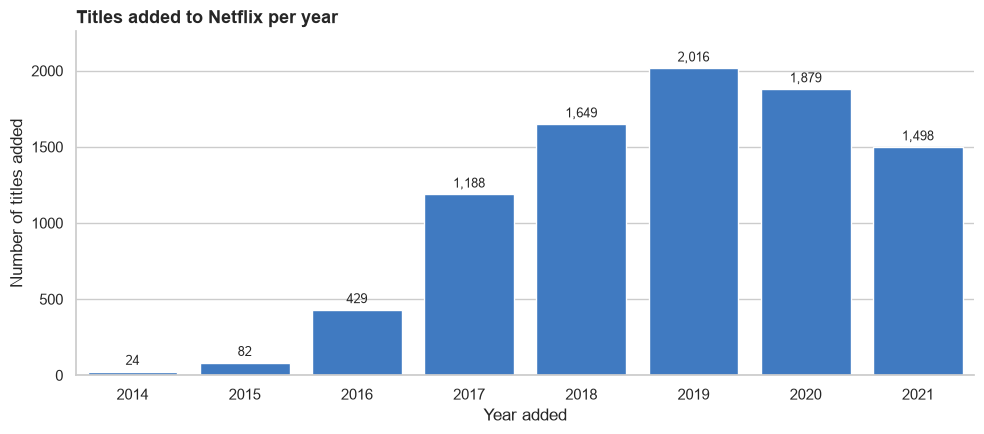

Year-over-year change (%): {2015: 241.7, 2016: 423.2, 2017: 176.9, 2018: 38.8, 2019: 22.3, 2020: -6.8, 2021: -20.3}
2015 -> 2019 multiple: 24.6x
Titles added before 2014: 32


In [28]:
added_per_year = clean["year_added"].value_counts().sort_index()
added_per_year = added_per_year[added_per_year.index >= 2014]  # only a few dozen titles were added before 2014

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(x=added_per_year.index, y=added_per_year.values, color=BLUE, ax=ax)
label_bars(ax)
style_ax(ax, "Titles added to Netflix per year", "Year added", "Number of titles added")
ax.set_ylim(0, added_per_year.max() * 1.12)
save_and_show(fig, "05_titles_added_per_year.png")

growth = added_per_year.pct_change() * 100
print("Year-over-year change (%):", growth.round(1).dropna().to_dict())
print(f"2015 -> 2019 multiple: {added_per_year[2019] / added_per_year[2015]:.1f}x")
print(f"Titles added before 2014: {(clean['year_added'] < 2014).sum()}")

Additions grew from **82** in 2015 to a peak of **2,016** in 2019, about **24.6×** in four years. 2017 alone was up **177%** on 2016. Additions then fell **6.8%** to 1,879 in 2020. The 2021 figure (1,498) only covers up to **25 September 2021**, so it isn't a full year and its drop shouldn't be read as a decline.

### Q3. Which 10 countries produce the most content, and how does the movie/TV mix differ?

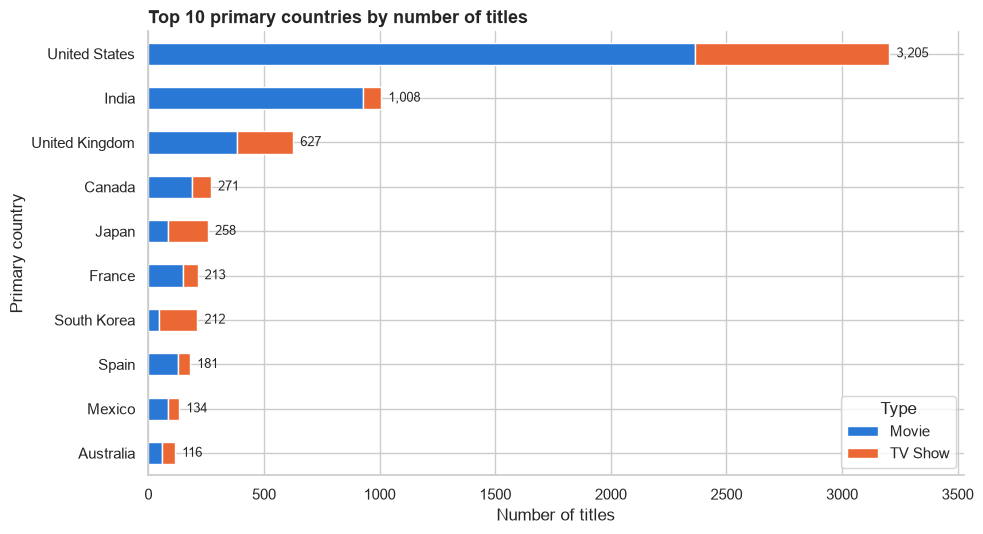

type             Movie  TV Show
primary_country                
United States     73.8     26.2
India             92.0      8.0
United Kingdom    60.9     39.1
Canada            69.0     31.0
Japan             32.9     67.1
France            70.0     30.0
South Korea       22.2     77.8
Spain             71.3     28.7
Mexico            64.2     35.8
Australia         52.6     47.4

US share of titles with a known country: 40.2%


In [29]:
known = clean[clean["primary_country"] != "Unknown"]
top_countries = known["primary_country"].value_counts().head(10).index
country_mix = (pd.crosstab(known["primary_country"], known["type"])
                 .loc[top_countries[::-1]])  # reverse so the largest is on top

fig, ax = plt.subplots(figsize=(10, 5.5))
country_mix.plot(kind="barh", stacked=True, color=[TYPE_COLORS[c] for c in country_mix.columns],
                 edgecolor="white", linewidth=1, ax=ax)
for i, total in enumerate(country_mix.sum(axis=1)):
    ax.text(total + 30, i, f"{total:,}", va="center", fontsize=9)
style_ax(ax, "Top 10 primary countries by number of titles", "Number of titles", "Primary country")
ax.set_xlim(0, country_mix.sum(axis=1).max() * 1.1)
ax.legend(title="Type", loc="lower right")
save_and_show(fig, "06_top_countries.png")

country_pct = (country_mix.div(country_mix.sum(axis=1), axis=0) * 100).round(1).iloc[::-1]
print(country_pct.to_string())
print(f"\nUS share of titles with a known country: {known['primary_country'].eq('United States').mean() * 100:.1f}%")

The **United States (3,205 titles)** dominates, accounting for **40.2%** of titles with a known country. **India (1,008)** and the **UK (627)** come next. The mix varies enormously by country: India's catalogue is **92.0% movies**, while **South Korea (77.8%)** and **Japan (67.1%)** are majority TV shows, driven by K-dramas and anime. The US mix (73.8% movies) is close to the overall average.

### Q4. What is the distribution of movie runtimes and TV show season counts?

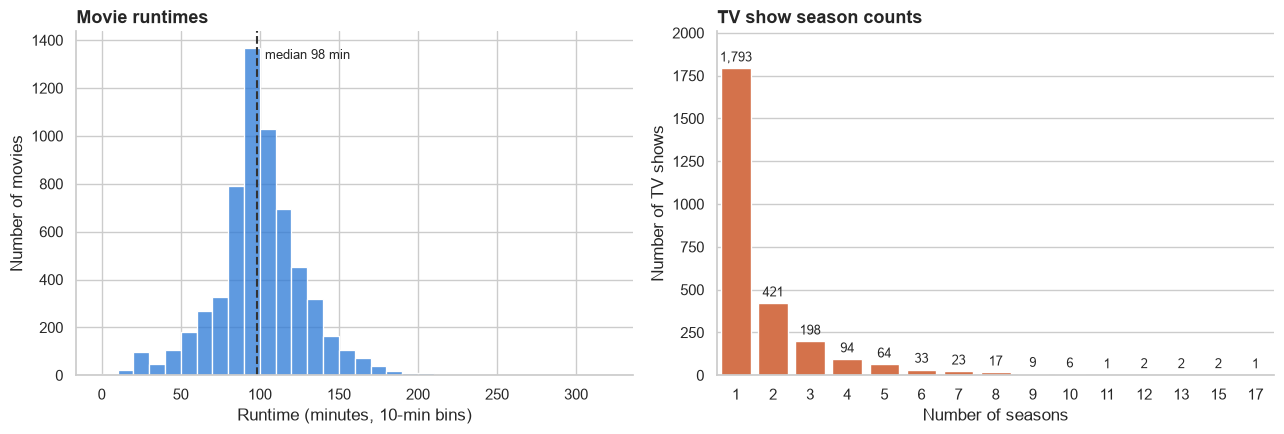

Movies: mean 99.6, median 98, share 80-120 min 64.2%
TV shows: 1 season 67.3%, 3+ seasons 17.0%


In [30]:
movies = clean[clean["type"] == "Movie"]
shows = clean[clean["type"] == "TV Show"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(movies["duration_minutes"], binwidth=10, binrange=(0, 320), color=BLUE, edgecolor="white", ax=ax1)
median_runtime = movies["duration_minutes"].median()
ax1.axvline(median_runtime, color="#333333", linestyle="--", linewidth=1.5)
ax1.annotate(f"median {median_runtime:.0f} min", (median_runtime, ax1.get_ylim()[1] * 0.92),
             xytext=(6, 0), textcoords="offset points", fontsize=9)
style_ax(ax1, "Movie runtimes", "Runtime (minutes, 10-min bins)", "Number of movies")

season_counts = shows["num_seasons"].astype(int).value_counts().sort_index()
sns.barplot(x=season_counts.index, y=season_counts.values, color=ORANGE, ax=ax2)
label_bars(ax2)
style_ax(ax2, "TV show season counts", "Number of seasons", "Number of TV shows")
ax2.set_ylim(0, season_counts.max() * 1.12)
save_and_show(fig, "07_durations.png")

print(f"Movies: mean {movies['duration_minutes'].mean():.1f}, median {median_runtime:.0f}, "
      f"share 80-120 min {movies['duration_minutes'].between(80, 120).mean() * 100:.1f}%")
print(f"TV shows: 1 season {season_counts[1] / len(shows) * 100:.1f}%, "
      f"3+ seasons {(shows['num_seasons'] >= 3).mean() * 100:.1f}%")

Movie runtimes are roughly bell-shaped around a **median of 98 minutes** (mean 99.6), and **64.2%** of movies run 80–120 minutes. A visible bump of short titles under 30 minutes comes from shorts and specials. TV shows are heavily skewed: **67.3% have just one season**, and only **17.0%** reach three or more. Many are limited series, or shows that weren't renewed.

### Q5. Which genres dominate, and do they differ between movies and TV shows?

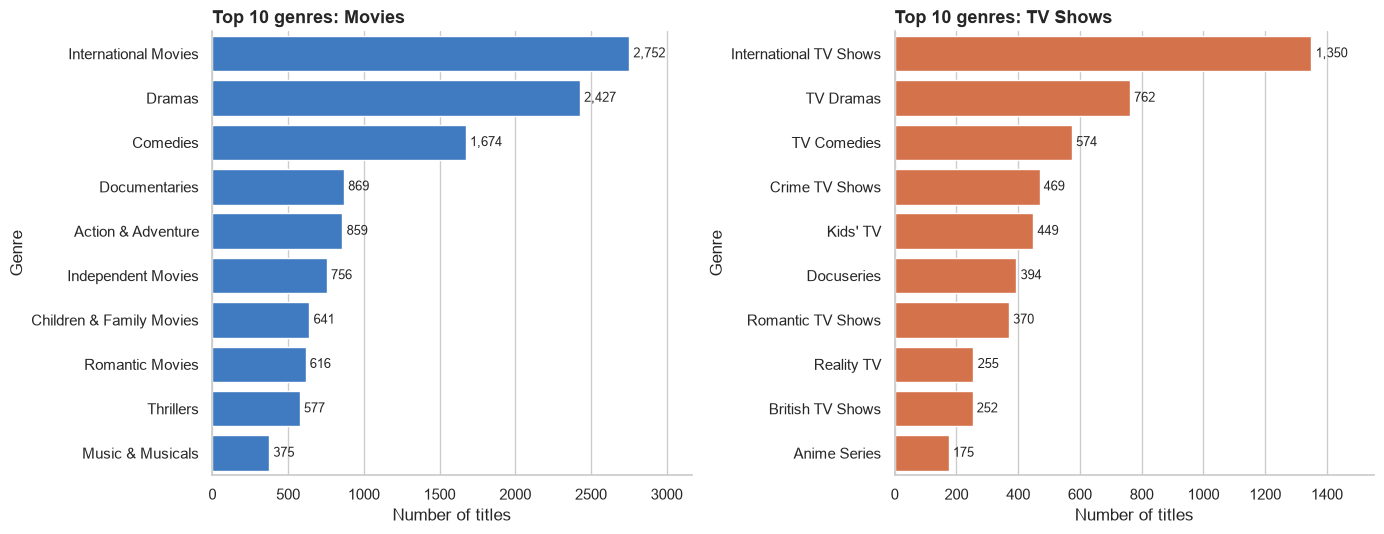

Movies tagged 'International Movies': 44.9%
TV shows tagged 'International TV Shows': 50.6%


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, content_type in zip(axes, ["Movie", "TV Show"]):
    top = genres.loc[genres["type"] == content_type, "genre"].value_counts().head(10)
    sns.barplot(x=top.values, y=top.index, color=TYPE_COLORS[content_type], ax=ax)
    label_bars(ax)
    style_ax(ax, f"Top 10 genres: {content_type}s", "Number of titles", "Genre")
    ax.set_xlim(0, top.max() * 1.15)
save_and_show(fig, "08_top_genres.png")

intl_movies = movies["listed_in"].str.contains("International Movies").mean() * 100
intl_tv = shows["listed_in"].str.contains("International TV Shows").mean() * 100
print(f"Movies tagged 'International Movies': {intl_movies:.1f}%")
print(f"TV shows tagged 'International TV Shows': {intl_tv:.1f}%")

"International" is the most common tag for both types: **44.9% of movies** and **50.6% of TV shows** carry it. After that, the two lists mirror each other (Dramas, Comedies and documentaries rank highly for both), but they differ further down. **Crime TV Shows (469)** is 4th for TV, while the movie top 10 has no crime category (the closest is Thrillers, 9th with 577). TV's top 10 also includes **Reality TV (255)**, **British TV Shows (252)** and **Anime Series (175)**, whereas movies rank **Action & Adventure (859)** and **Independent Movies (756)** highly.

### Q6. What audience-maturity ratings are most common?

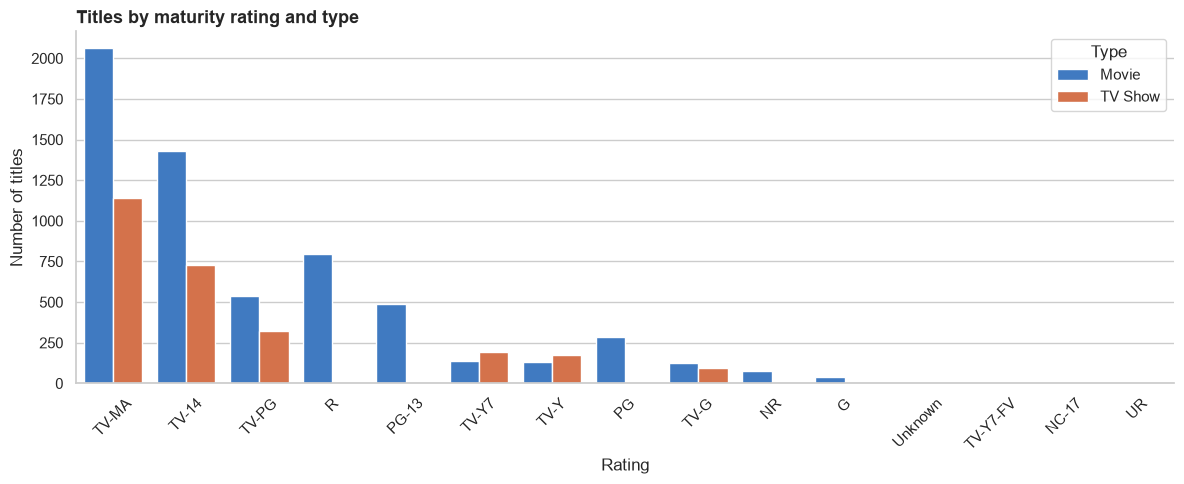

rating
TV-MA    36.4
TV-14    24.5
TV-PG     9.8
R         9.1
PG-13     5.6

Adult-only (TV-MA, R, NC-17): 45.5%   Kids/all-ages (TV-Y, TV-Y7, TV-Y7-FV, TV-G, G): 10.3%


In [32]:
rating_order = clean["rating"].value_counts().index
fig, ax = plt.subplots(figsize=(12, 5))
sns.countplot(data=clean, x="rating", hue="type", order=rating_order,
              palette=TYPE_COLORS, ax=ax)
style_ax(ax, "Titles by maturity rating and type", "Rating", "Number of titles")
ax.tick_params(axis="x", rotation=45)
ax.legend(title="Type")
save_and_show(fig, "09_ratings.png")

rating_share = clean["rating"].value_counts(normalize=True) * 100
adult = clean["rating"].isin(["TV-MA", "R", "NC-17"]).mean() * 100
kids = clean["rating"].isin(["TV-Y", "TV-Y7", "TV-Y7-FV", "TV-G", "G"]).mean() * 100
print(rating_share.head(5).round(1).to_string())
print(f"\nAdult-only (TV-MA, R, NC-17): {adult:.1f}%   Kids/all-ages (TV-Y, TV-Y7, TV-Y7-FV, TV-G, G): {kids:.1f}%")

**TV-MA** is the single most common rating (**36.4%** of titles), followed by **TV-14 (24.5%)**. Together, adult-only ratings (TV-MA, R, NC-17) cover **45.5%** of the catalogue, compared with **10.3%** for kids' and all-ages ratings. So the catalogue skews clearly towards mature audiences. Film ratings (R, PG-13, PG) show up almost only on movies, because TV shows use the TV- rating scale.

### Q7. How old is content when it's added to Netflix?

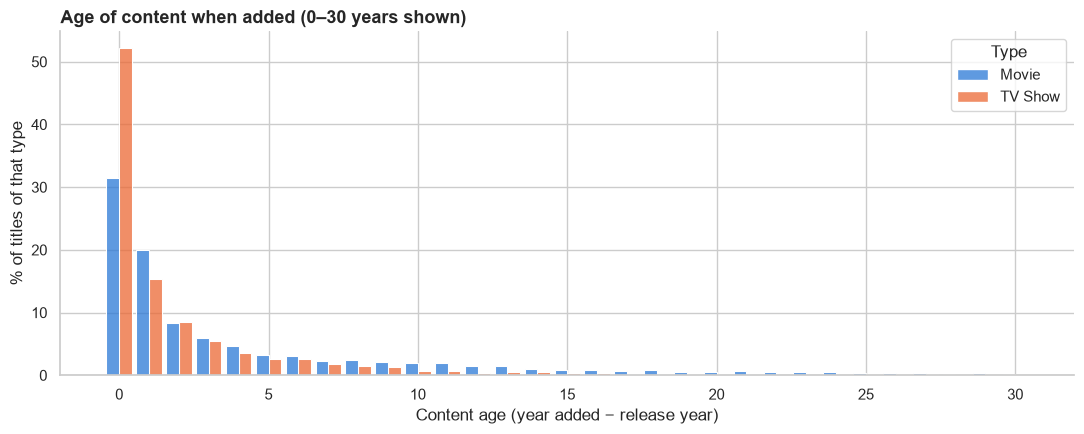

Median content age: 1 year(s) (mean 4.7)
Added in the year of release: 36.8%;  within 1 year: 55.0%
Median by type: {'Movie': 2.0, 'TV Show': 0.0}
Older than 30 years (not shown): 231 titles; negative ages (not shown): 14


In [33]:
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.histplot(data=clean[clean["content_age"].between(0, 30)], x="content_age", hue="type",
             discrete=True, stat="percent", common_norm=False, multiple="dodge",
             palette=TYPE_COLORS, shrink=0.85, ax=ax)
style_ax(ax, "Age of content when added (0–30 years shown)",
         "Content age (year added − release year)", "% of titles of that type")
ax.get_legend().set_title("Type")
save_and_show(fig, "10_content_age.png")

age = clean["content_age"]
print(f"Median content age: {age.median():.0f} year(s) (mean {age.mean():.1f})")
print(f"Added in the year of release: {(age == 0).mean() * 100:.1f}%;  within 1 year: {(age <= 1).mean() * 100:.1f}%")
print("Median by type:", clean.groupby("type")["content_age"].median().to_dict())
print(f"Older than 30 years (not shown): {(age > 30).sum()} titles; negative ages (not shown): {(age < 0).sum()}")

Most content is fresh. **36.8%** of titles were added in the same year they were released and **55.0%** within one year, giving a **median age of 1 year**. The mean is higher (4.7 years) because of a long tail of classics. TV shows are added faster than movies (**median 0 vs 2 years**), consistent with Netflix originals and simultaneous international releases making up much of its TV slate.

### Q8. Which months see the most additions?

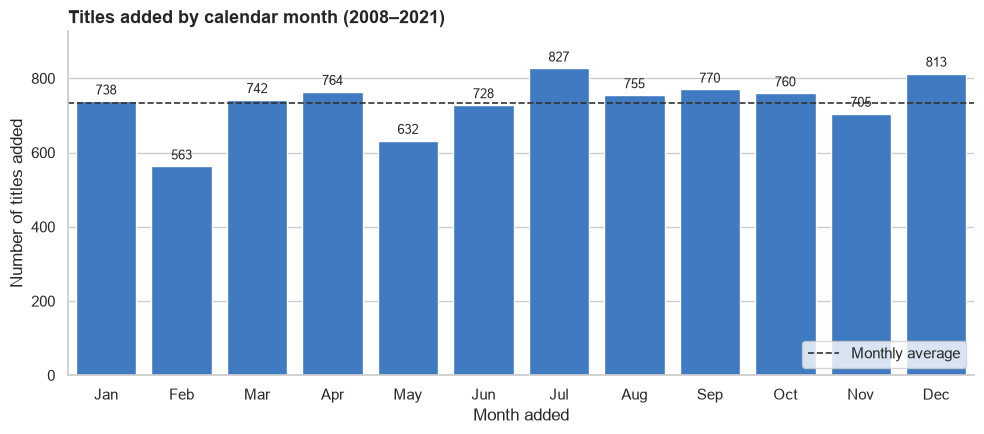

Busiest: Jul (827), quietest: Feb (563), average 733


In [34]:
month_counts = clean["month_added"].value_counts().sort_index()
month_labels = [calendar.month_abbr[m] for m in month_counts.index]

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(x=month_labels, y=month_counts.values, color=BLUE, ax=ax)
ax.axhline(month_counts.mean(), color="#333333", linestyle="--", linewidth=1.2, label="Monthly average")
label_bars(ax)
style_ax(ax, "Titles added by calendar month (2008–2021)", "Month added", "Number of titles added")
ax.set_ylim(0, month_counts.max() * 1.12)
ax.legend(loc="lower right")
save_and_show(fig, "11_month_added.png")

print(f"Busiest: {month_labels[month_counts.argmax()]} ({month_counts.max()}), "
      f"quietest: {month_labels[month_counts.argmin()]} ({month_counts.min()}), "
      f"average {month_counts.mean():.0f}")

Additions are spread fairly evenly through the year (about **733 per month** on average). **July (827)** and **December (813)** are the busiest months, in line with summer and holiday viewing, and **February (563)** is the quietest. Part of February's dip is simply that it has fewer days. Because the 2021 data stops in September, October to December are slightly under-counted relative to the other months.

### Q9. Are the numeric features related? (correlation heatmap, movies only)

`duration_minutes` and `num_seasons` never overlap, because a title is either a movie or a show, so the correlation is computed on movies only, where runtime is defined.

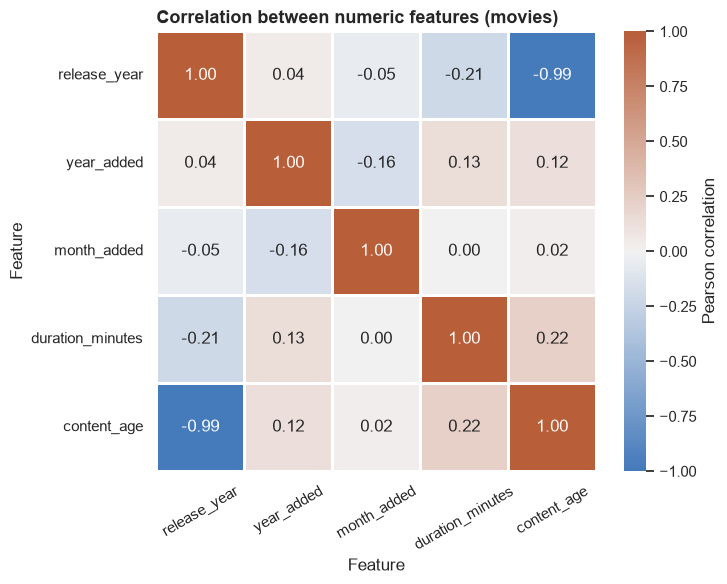

                  release_year  year_added  month_added  duration_minutes  content_age
release_year              1.00        0.04        -0.05             -0.21        -0.99
year_added                0.04        1.00        -0.16              0.13         0.12
month_added              -0.05       -0.16         1.00              0.00         0.02
duration_minutes         -0.21        0.13         0.00              1.00         0.22
content_age              -0.99        0.12         0.02              0.22         1.00


In [35]:
corr_cols = ["release_year", "year_added", "month_added", "duration_minutes", "content_age"]
corr = movies[corr_cols].corr()

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1, square=True, linewidths=1,
            cmap=sns.diverging_palette(250, 25, center="light", as_cmap=True),
            cbar_kws={"label": "Pearson correlation"}, ax=ax)
style_ax(ax, "Correlation between numeric features (movies)", "Feature", "Feature")
ax.tick_params(axis="x", rotation=30)
save_and_show(fig, "12_correlation_heatmap.png")

print(corr.round(2).to_string())

Most features are only weakly related. The strong **−0.99** between `release_year` and `content_age` is expected, because content age is computed from release year. The more interesting signal is **runtime vs release year (−0.21)** and **runtime vs content age (+0.22)**: older films added to Netflix tend to run longer than recent ones. `month_added` is essentially unrelated to everything else.

## 7. Key findings

1. **The missing director data is structural, not random.** 91.4% of TV shows have no director, compared with 3.1% of movies, because series are directed episode by episode. Any analysis of "top directors" is really an analysis of movies only.
2. **Netflix's TV push dipped and then came back.** TV shows were 41% of additions in 2016, fell to 25% in 2018 during a bulk movie-licensing phase, and rose every year after that to 33.7% in 2021.
3. **Country of origin almost determines format.** India's catalogue is 92.0% movies, while South Korea's (77.8%) and Japan's (67.1%) are mostly TV shows. Regional strengths (Bollywood films vs K-dramas and anime) show up directly in the catalogue.
4. **Netflix adds fresh content, and TV even faster.** 36.8% of titles were added in their release year and 55.0% within a year. The median TV show is added in its release year (age 0), versus 2 years for movies.
5. **Most series end after one season.** 67.3% of TV shows have a single season and only 17.0% reach three or more. Combined with additions peaking at 2,016 titles in 2019, this shows a strategy built on volume and churn rather than long-running franchises.

### Limitations

- **Snapshot in time:** the data reflects the catalogue as of **25 September 2021**. 2021 is a partial year, and titles that had already been removed before the snapshot aren't included (survivorship bias), so the "per year" trends describe *what survived*, not everything that was added.
- **Region:** the dataset doesn't say which countries' catalogues each title is available in, so "Netflix" here means the dataset as published, not any one regional catalogue.
- **Missing and simplified fields:** `director` (29.9%), `country` (9.4%) and `cast` (9.4%) have gaps. `primary_country` keeps only the first of several countries for the 15% of co-productions.
- **Coarse measures:** TV duration is measured in seasons, not episodes or hours, so it can't be compared with movie runtimes. Genres are Netflix's own overlapping tags, and "International" is applied very widely.
- **Data quality:** 14 titles have a negative content age and 3 ratings had been entered in the wrong column (fixed here), which suggests other undetected entry errors may exist.